### Imports


In [1]:
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd()))   

from src import data as D       
from src import hvg as H        
from src import metrics as M    
from src import splits as S     
import numpy as np, pandas as pd
import scvi
from scvi.external import MRVI
import scanpy as sc
import matplotlib.pyplot as plt

c:\Users\19aca\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


###  Load data and attach the folds

`load_adata()` finds `wu2021_brca.h5ad` automatically and fixes the layout: in the file `.X` is
already log1p-CP10k and the counts are in `.raw`, so after loading `adata.X` = **raw integer counts**
(what scVI/MrVI and seurat_v3 HVG need) and `adata.layers["lognorm"]` = log1p-CP10k (for PCA-like
baselines). Never apply `log1p` again. `attach_folds()` reads
`data/splits.parquet` (the 26-patient table from notebook 01) and maps each patient's
`fold_5 / fold_lopo / fold_batch` onto every cell via `donor_id`.

In [2]:
adata = D.load_adata()  # the real data: cells x genes
D.attach_folds(adata) # adds obs['fold_5'], obs['fold_lopo'], obs['fold_batch']
print(adata)
adata.obs[['donor_id','fold_5','fold_lopo','fold_batch']].drop_duplicates('donor_id').head() # Safety head drop duplicates

AnnData object with n_obs × n_vars = 100064 × 28523
    obs: 'donor_id', 'percent_mito', 'nCount_RNA', 'nFeature_RNA', 'celltype_major', 'celltype_minor', 'celltype_subset', 'subtype', 'gene_module', 'calls', 'normal_cell_call', 'CNA_value', 'batch_run', 'multiplexed', 'cryo_state', 'development_stage_ontology_term_id', 'cancer_type', 'ER', 'PR', 'HER2_IHC', 'HER2_ISH', 'HER2_ISH_ratio', 'Ki67', 'subtype_by_IHC', 'treatment_status', 'treatment_details', 'assay_ontology_term_id', 'tissue_ontology_term_id', 'suspension_type', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'is_primary_data', 'disease_ontology_term_id', 'grade', 'cell_type_ontology_term_id', 'tissue_type', 'HER2_ISH_legacy', 'cell_type_ontology_term_id_legacy', 'celltype_major_legacy', 'celltype_minor_legacy', 'celltype_subset_legacy', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'fold_5', 'fold_lopo', 'fold_batch'
    var: 'fea

,donor_id,fold_5,fold_lopo,fold_batch
CID3586_AAGACCTCAGCATGAG,CID3586,3,0,13
CID3921_AAAGATGGTGAGGCTA,CID3921,2,2,12
CID45171_CATCAAGTCAACACCA,CID45171,4,25,9
CID3838_AAACGCTAGAGCCGAT,CID3838,1,1,16
CID4066_ACTGCTCTCTCGATGA,CID4066,0,8,12


###  Fold

`fold_mask(adata, scheme, test_value)` returns boolean `train_mask, test_mask` with no cell
of a patient split across the two. We then select HVG on train only (`select_hvg_train`)
so feature selection never sees the test patient.

In [3]:
SCHEME, TEST_FOLD = "fold_5", 0
train_mask, test_mask = D.fold_mask(adata, SCHEME, TEST_FOLD)
print(f"{SCHEME}=={TEST_FOLD}:  train cells = {train_mask.sum():,}   test cells = {test_mask.sum():,}")

N_HVG = 2500
hvg = H.select_hvg_train(adata, train_mask, n_top=N_HVG) # computed on TRAIN cells only
print("HVG selected on train:", len(hvg))

fold_5==0:  train cells = 78,344   test cells = 21,720
HVG selected on train: 2503


### MrVI

MrVI (Multi-Resolution Variational Inference) [P.Boyeau et al, 2025](https://www.nature.com/articles/s41592-025-02808-x) is a deep generative model designed for exploratory and comparative analysis of single-cell sequencing data from multiple samples

Takes as input two types of sample-level covariates:

- Target Covariates: (sample-level target covariates). Which refer to actual properties. It usually represents the sample ID which defined what entities will be compared. (In our case, they will be the sample ID). Given by: $s_n$

- Nuisance Covariates: Corresponds to technical factors (study of origin, sample processing site....) Given by: $b_n$

####  MrVI process

![MrVI Graphical Model](images/MrVi.png)

Image taken from [scvi-tools](https://docs.scvi-tools.org/en/1.3.3/user_guide/models/mrvi.html)

The idea from MrVI is that each cell (n) is associated with two latent variables $u_n, z_n$

- **$u_n$**: Captures the variation between cell states without taking into account the sample covariates. Given by a Gaussian Mixture prior $u_n \sim MixtureOfGaussians(\mu_1, ..., \mu_k, \sum_1, ..., \sum_K, \pi_1, ..., \pi_K)$

- **$z_n$**: Captures the variation between cell states, taking into account the sample covariates but remaining unaffected by nuisance covariates. It is actually learnt from $u_n$ as well as the target covariates. $z_n|u_n \sim N(u_n, I_L)$. This allows for comparative analysis, as a useful question we could extract from this would be: "If cell n, originally in patient A (s), cambe from patient B (s'), how would the state $z_n$ look like". This is one of the main advantages of MrVI

- **$x_n$**: Models raw gene counts by decoding $z_n$ conditioned on nuisance covariates $b_n$ and cell library size $l_n$ using a Negative Binomial distribution:
  $$x_n \mid z_n, b_n \sim \text{NegativeBinomial}(\mu(z_n, b_n), r)$$

Actual $x_n$ is computed using $h_n$ which receives the latent $z_n$ and nuisance factors $b_n$ which pass through a multi-head attention layer so the output is normalized (this also uses a specific matrix and bias, more details in the paper)

#### MrVI Inference

Variatonal inference is used to approximate the posterior of $u_n$ and $z_n$.

$q_\phi (u_n|x_n) = N(\mu_\phi (x_n), \sigma_\phi^2(x_n)I$

$z_n = u_n + f_\phi(u_n, s_n)$

Where the values are given by neural networks such as encoders or using multi-head attention

**Important: Model is already trained, if RETRAIN is set to FALSE above, this will load the already existing model**


In [4]:
scvi.settings.seed = S.SEED

N_LATENT = 10 # Chosen inside the PCA.ipynb 
RETRAIN = False
MODELS_DIR = pathlib.Path("models") / "MrVI"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Different model paths for the different splits
SPLIT_NAMES = {"fold_5": "5fold", "fold_batch": "lobo", "fold_lopo": "lopo"}
split_tag = SPLIT_NAMES.get(SCHEME, SCHEME)
model_path = MODELS_DIR / f"MrVI_{split_tag}_fold{TEST_FOLD}.pt"

# Loading the data
adata_train = adata[train_mask, hvg].copy()
MRVI.setup_anndata(adata_train, layer=None, sample_key="donor_id")

# Training the model
if model_path.exists() and not RETRAIN:
    mrvi_model = MRVI.load(model_path, adata=adata_train)
else:
    mrvi_model = MRVI(adata_train, n_latent=N_LATENT)
    mrvi_model.train(max_epochs=400, early_stopping=True, check_val_every_n_epoch=1)
    mrvi_model.save(model_path, overwrite=True)


Seed set to 42


INFO     File models\MrVI\MrVI_5fold_fold0.pt\model.pt already downloaded                                          


C:\Users\19aca\AppData\Local\Temp\ipykernel_30392\3706448102.py:19: UserWarning: MRVI model is being loaded with PyTorch backend
  mrvi_model = MRVI.load(model_path, adata=adata_train)
c:\Users\19aca\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\scvi\external\mrvi\_model.py:158: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  self.n_obs_per_sample = torch.Tensor(


In [ ]:
adata_test = adata[test_mask, hvg].copy()
MRVI.prepare_query_anndata(adata_test, mrvi_model)
query_model = MRVI.load_query_data(adata_test, mrvi_model)
query_model.is_trained_ = True

Z = np.zeros((adata.n_obs, N_LATENT), dtype=np.float32)
Z[train_mask] = mrvi_model.get_latent_representation(adata_train, give_z=False)
Z[test_mask] = query_model.get_latent_representation(adata_test, give_z=False)
adata.obsm["X_mrvi_u"] = Z

adata_train.obsm["X_mrvi_u"] = Z[train_mask]
adata_train.obsm["X_mrvi_z"] = mrvi_model.get_latent_representation(adata_train, give_z=True) # Give z passes patient

print(f"Model path: {model_path} | Z: {Z.shape}")

INFO     Found 100.0% reference vars in query data.                                                                
Model path: models\MrVI\MrVI_5fold_fold0.pt | Z: (100064, 10)


The ELBO loss for this model is given by:

$$
ELBO(\theta, \phi) = E_{x,s,b} E_{q_\phi(u|x)}[\log \frac{p_\theta(x|z,b) p_\theta(z|u,s) p_\theta(u)}{q_\phi(u|x)}]
$$

This is just for understanding purposes, it is also important to note that the final ELBO loss actually includes a penalty term to ensure that there is a distance between z and u so they do not represent the same element

Visualizing the ELBO loss to see for convergence or potential overfitting.

history keys: ['kl_weight', 'validation_loss', 'elbo_validation', 'reconstruction_loss_validation', 'kl_local_validation', 'kl_global_validation', 'train_loss', 'elbo_train', 'reconstruction_loss_train', 'kl_local_train', 'kl_global_train']


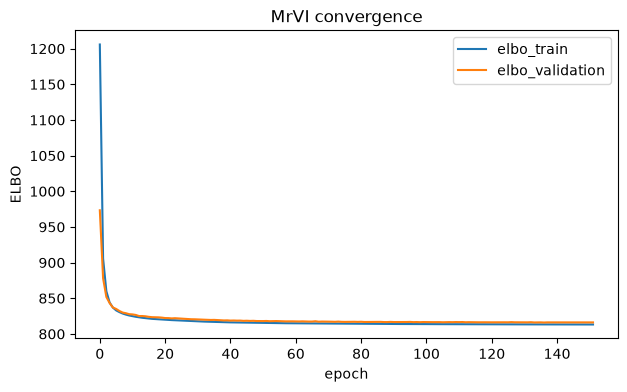

In [6]:
if mrvi_model.history:
    h = mrvi_model.history
    print("history keys:", list(h.keys()))
    fig, ax = plt.subplots(figsize=(7, 4))
    for key in ("elbo_train", "elbo_validation"):
        if key in h:
            ax.plot(h[key].values.ravel(), label=key)
    ax.set(xlabel="epoch", ylabel="ELBO", title="MrVI convergence")
    ax.legend()
    plt.show()
else:
    print("Loaded saved model from disk; training history is not stored in checkpoint.")

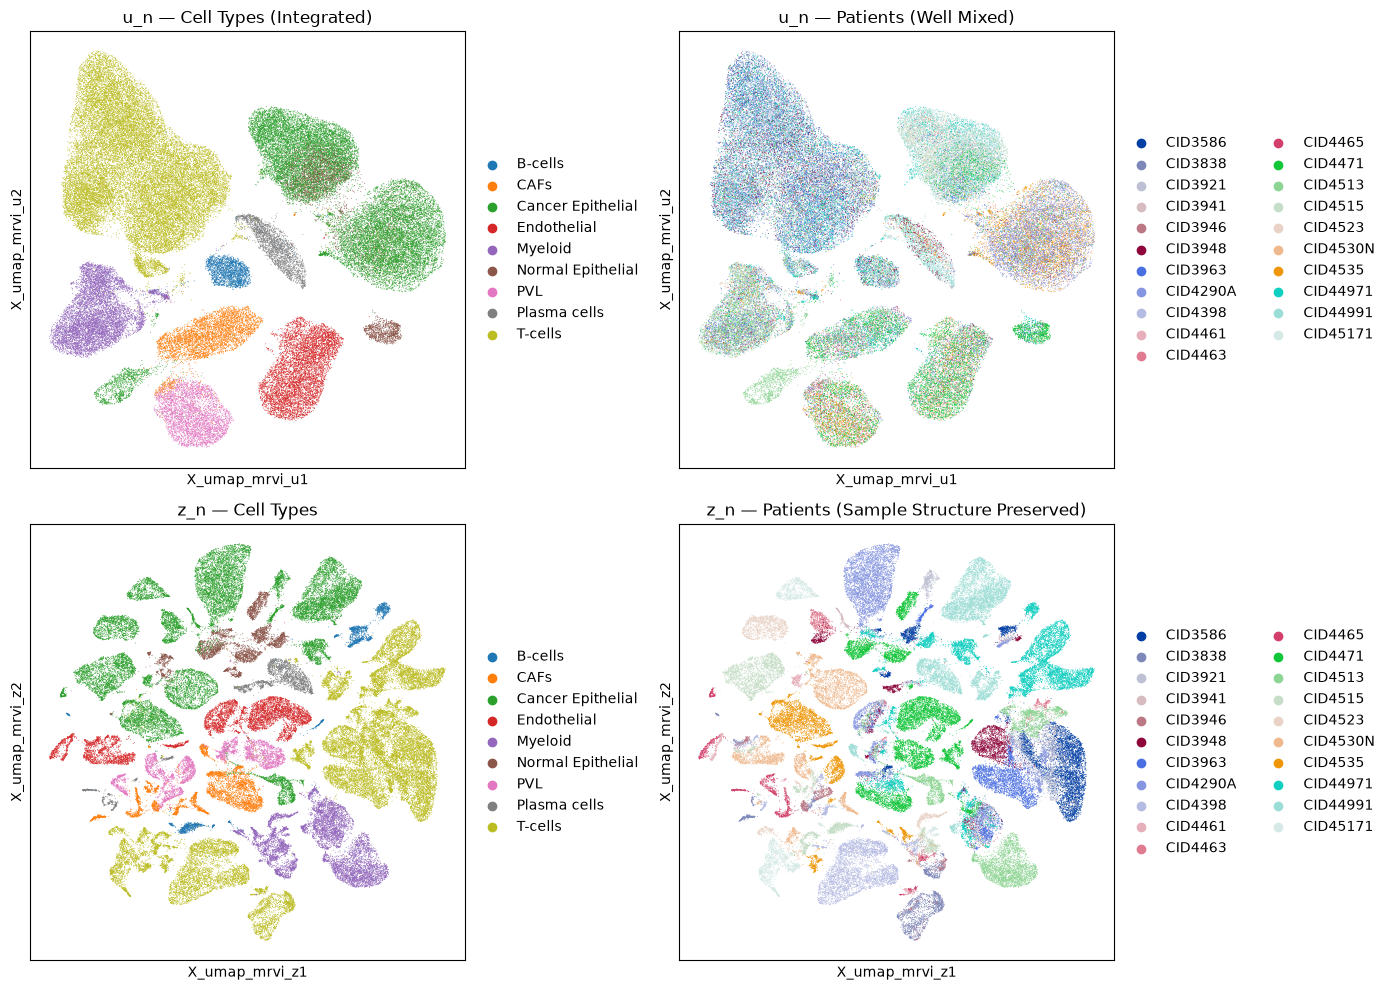

In [7]:
sc.pp.neighbors(adata_train, use_rep="X_mrvi_u", key_added="mrvi_u_neighbors")
sc.tl.umap(adata_train, neighbors_key="mrvi_u_neighbors")
adata_train.obsm["X_umap_mrvi_u"] = adata_train.obsm["X_umap"].copy()

sc.pp.neighbors(adata_train, use_rep="X_mrvi_z", key_added="mrvi_z_neighbors")
sc.tl.umap(adata_train, neighbors_key="mrvi_z_neighbors")
adata_train.obsm["X_umap_mrvi_z"] = adata_train.obsm["X_umap"].copy()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sc.pl.embedding(
    adata_train,
    basis="X_umap_mrvi_u",
    color="celltype_major",
    ax=axes[0, 0],
    show=False,
    title="u_n — Cell Types (Integrated)",
)
sc.pl.embedding(
    adata_train,
    basis="X_umap_mrvi_u",
    color="donor_id",
    ax=axes[0, 1],
    show=False,
    title="u_n — Patients (Well Mixed)",
)

sc.pl.embedding(
    adata_train,
    basis="X_umap_mrvi_z",
    color="celltype_major",
    ax=axes[1, 0],
    show=False,
    title="z_n — Cell Types",
)
sc.pl.embedding(
    adata_train,
    basis="X_umap_mrvi_z",
    color="donor_id",
    ax=axes[1, 1],
    show=False,
    title="z_n — Patients (Sample Structure Preserved)",
)

plt.tight_layout()
plt.show()

We can see 4 separate graphs

First row displays the latent from u.

- Left Displays cell populations grouped into distinct clusters

- Right: Pattient labels

The main idea we can extract from here is that the latent space for $u_n$ clearly isolated cell identity without taking into account donor-specific covariates

Bottom row displays the latent from z.

- Left: Split by cell type, however, we can see that the main cells are split, dont show clear clusters as in the above one.

- Right: Align directly with patient IDs. Shows the effect of introducing target sample covariates $s_n$ in this case, patient ID which captures donor-to-donor variation

Cancer epithelial cells group together clearly for the latent space $u_n$. In $z_n$ cancer epithelial cells split into specific patients, showing variation across patients.

As explained before, $u_n$ is a latent which is used for storing the variation between cell states. Therefore it consistenly outperforms $z_n$ for each of the cell-type metrics. Batch entropy is much higher showing that clearly this latent removes patient effects.

$z_n$ preserves patient-level variation. This explains the decline in batch entropy metrics as well as a much lower ASW (patient). This supports our UMAP representation above.

The first latent will be better for cell-type clustering as well as any task requiring elimination of batch noise. The second latent will be useful to study patient-specific problems if needed.

### Evaluation Metrics

The metrics we will use to evaluate the model will be applied at latent space level.They will be used to asses the quality of preserving cell-type identity as well as integrating patient samples. They are taken from some of the papers in the literature such as the Benchmarking paper [M.D. Luecken et. Al.](https://www.nature.com/articles/s41592-021-01336-8).
These are:

- **[Adjusted Rand Index (ARI)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html)**:  Evaluates the similarity between two clustering assignments. Takes the Rand Index (RI) which computes the percentage of correct decisions comparing the predicted clusters to the true labels. In our case, we compare to the true cell-type labels. However, random assignments could have positive values, which is addressed by Adjusted Rand Index. Returns a value between -1 and 1. 1 means perfect classification, 0 corresponds to random cluster assignment

- **[Normalized Mutual Information (NMI)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.normalized_mutual_info_score.html)**: Mutual Information splits according to clusters and according to class labels. Then, it quantifies how these two splittings agree with each other. However, MI gets large if the number of clusters is large. Therefore, this number is normalized to be between 0 (no mutual information) and 1 (perfect correlation). The higher the better

- **[Average Silhouette Width (ASW)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)**: Measures how close an element is to its own cluster while comparing to its other clusters. Returns a value between -1 and 1, where negative values will correspond to when a sample has been assigned to the wrong cluster, positive values indicate good clustering. Values close to 0 are for overlapping clusters.

    The intepretation for this value depends on whether if we want to inspect quality of preserving cell-type identity or integrating patient samples.
    *ASW (cell):* The grouping variable will be the cell-type, we want this value to be high as cells of the same type should form isolated clusters in latent space.
    *ASW(patient):* If this value is high, it means that cells are clustering by patient rather than by biology elements.Therefore we want values closer to 0, as patients contain technical effects, which are usually unwanted (technical effects could be being inspected by a different doctor, different hospital, different times...)

- **Batch Entropy**: Measures the local mixing of a label in the k-nearest neighbor (kNN) graph around each cell. For every cell, the algorithm creates a neighborhood of its k nearest neighbors. (In the below function we use k=50, this will be the same for all models). A low value means that a cell neighborhood has cells from a single label.This can be used to compute for patients -> 'labels=adata.obs["batch_run"]' or 'labels=adata.obs["batch_run"]' are some of the possible options. 

    Our current batch entropy evaluates K=50 neighbors, as we have less number of patients and batch runs, is is possible that the theoretical maximum is slightly lower than 1, we will compute it so we can use it for reference when we obtain values.

In [8]:
te = test_mask
scores = M.evaluate_embedding(
    Z=Z[te],
    cell_type=adata.obs["celltype_major"].values[te],
    patient=adata.obs["donor_id"].values[te],
    batch_run=adata.obs["batch_run"].values[te],
    k=50,
    asw_sample_size=20000,
    seed=S.SEED,
)
print("test fold", TEST_FOLD, "->", {k: round(v, 3) for k, v in scores.items()})

test fold 0 -> {'ARI': 0.921, 'NMI': 0.891, 'ASW_celltype': 0.722, 'ASW_patient': 0.004, 'Patient_Entropy': 0.25, 'Batch_Run_Entropy': 0.25}


###  Loop over every fold (cross-validation)

`iter_folds` yields `(test_value, train_mask, test_mask)` for the whole scheme. 

In [ ]:
rows = []
split_tag = SPLIT_NAMES.get(SCHEME, SCHEME)

for test_value, tr, te in D.iter_folds(adata, scheme=SCHEME):
    hvg_k = H.select_hvg_train(adata, tr, n_top=N_HVG)

    # Fitting MrVI on this folds training donors only
    adata_tr = adata[tr, hvg_k].copy()
    MRVI.setup_anndata(adata_tr, layer=None, sample_key="donor_id")

    fold_path = MODELS_DIR / f"MrVI_{split_tag}_fold{test_value}.pt"
    if fold_path.exists() and not RETRAIN:
        m_k = MRVI.load(fold_path, adata=adata_tr)
    else:
        m_k = MRVI(adata_tr, n_latent=N_LATENT)
        m_k.train(max_epochs=400,batch_size=512, early_stopping=True, check_val_every_n_epoch=1)
        m_k.save(fold_path, overwrite=True)

    adata_te = adata[te, hvg_k].copy()
    MRVI.prepare_query_anndata(adata_te, m_k)
    q_k = MRVI.load_query_data(adata_te, m_k)
    q_k.is_trained_ = True
    Z_te = q_k.get_latent_representation(adata_te, give_z=False)
    
    s = M.evaluate_embedding(
        Z=Z_te,
        cell_type=adata.obs["celltype_major"].values[te],
        patient=adata.obs["donor_id"].values[te],
        batch_run=adata.obs["batch_run"].values[te],
        k=50,
        seed=S.SEED,
    )
    s["fold"] = test_value
    rows.append(s)

res = pd.DataFrame(rows).set_index("fold")
print(res.round(3))
print("\nMEAN:", res.mean(numeric_only=True).round(3).to_dict())
print("STD :", res.std(numeric_only=True).round(3).to_dict())

INFO     File models\MrVI\MrVI_5fold_fold3.pt\model.pt already downloaded                                          


C:\Users\19aca\AppData\Local\Temp\ipykernel_30392\947322724.py:14: UserWarning: MRVI model is being loaded with PyTorch backend
  m_k = MRVI.load(fold_path, adata=adata_tr)


INFO     Found 100.0% reference vars in query data.                                                                


C:\Users\19aca\AppData\Local\Temp\ipykernel_30392\947322724.py:16: DeprecationWarning: You are using the Torch Version of MrVI, starting v1.4.3, This will become the default version of MrVI instead of the Jax backend version, which will be removed in v1.5
  m_k = MRVI(adata_tr, n_latent=N_LATENT)
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
c:\Users\19aca\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\19aca\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not

Epoch 210/400:  52%|█████▎    | 210/400 [29:30<26:41,  8.43s/it, v_num=1, train_loss=771]
Monitored metric elbo_validation did not improve in the last 15 records. Best score: 780.511. Signaling Trainer to stop.
INFO     Found 100.0% reference vars in query data.                                                                


C:\Users\19aca\AppData\Local\Temp\ipykernel_30392\947322724.py:16: DeprecationWarning: You are using the Torch Version of MrVI, starting v1.4.3, This will become the default version of MrVI instead of the Jax backend version, which will be removed in v1.5
  m_k = MRVI(adata_tr, n_latent=N_LATENT)
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
c:\Users\19aca\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\19aca\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not

Epoch 241/400:  60%|██████    | 241/400 [34:08<22:31,  8.50s/it, v_num=1, train_loss=808]
Monitored metric elbo_validation did not improve in the last 15 records. Best score: 807.437. Signaling Trainer to stop.
INFO     Found 100.0% reference vars in query data.                                                                


C:\Users\19aca\AppData\Local\Temp\ipykernel_30392\947322724.py:16: DeprecationWarning: You are using the Torch Version of MrVI, starting v1.4.3, This will become the default version of MrVI instead of the Jax backend version, which will be removed in v1.5
  m_k = MRVI(adata_tr, n_latent=N_LATENT)
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
c:\Users\19aca\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\19aca\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not

Epoch 275/400:  69%|██████▉   | 275/400 [44:21<20:09,  9.68s/it, v_num=1, train_loss=751]
Monitored metric elbo_validation did not improve in the last 15 records. Best score: 751.246. Signaling Trainer to stop.
INFO     Found 100.0% reference vars in query data.                                                                
INFO     File models\MrVI\MrVI_5fold_fold0.pt\model.pt already downloaded                                          


C:\Users\19aca\AppData\Local\Temp\ipykernel_30392\947322724.py:14: UserWarning: MRVI model is being loaded with PyTorch backend
  m_k = MRVI.load(fold_path, adata=adata_tr)


INFO     Found 100.0% reference vars in query data.                                                                
        ARI    NMI  ASW_celltype  ASW_patient  Patient_Entropy  \
fold                                                             
3     0.560  0.769         0.706       -0.009            0.282   
2     0.631  0.766         0.691        0.033            0.213   
4     0.540  0.760         0.718        0.087            0.275   
1     0.865  0.878         0.724        0.055            0.203   
0     0.921  0.890         0.721        0.009            0.220   

      Batch_Run_Entropy  
fold                     
3                 0.272  
2                 0.213  
4                 0.275  
1                 0.203  
0                 0.220  

MEAN: {'ARI': 0.703, 'NMI': 0.813, 'ASW_celltype': 0.712, 'ASW_patient': 0.035, 'Patient_Entropy': 0.239, 'Batch_Run_Entropy': 0.237}
STD : {'ARI': 0.177, 'NMI': 0.066, 'ASW_celltype': 0.013, 'ASW_patient': 0.038, 'Patient_Entropy': 0.037

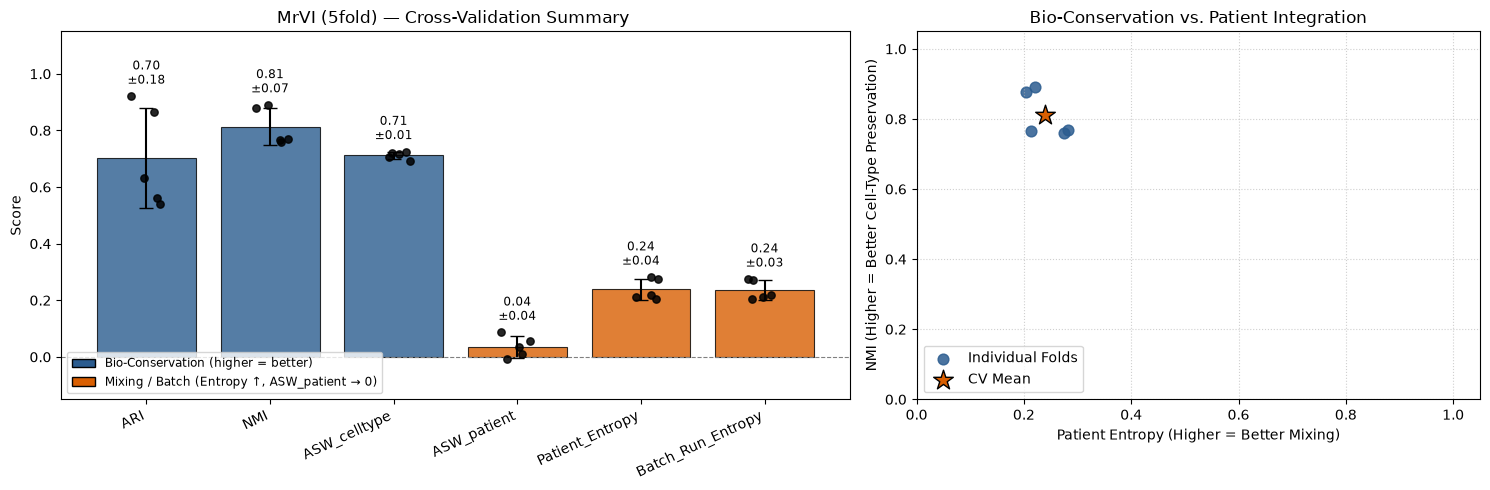

In [ ]:
res_plot = res.copy()

metrics = list(res_plot.columns)
means = res_plot[metrics].mean()
stds = res_plot[metrics].std()

# Color-code bio-conservation vs. batch/patient-mixing metrics
bio_metrics = {"ARI", "NMI", "ASW_celltype"}
colors = ["#2b5c8f" if m in bio_metrics else "#d95f02" for m in metrics]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.4, 1]})

# Mean and std per group
ax = axes[0]
x = np.arange(len(metrics))
bars = ax.bar(x, means, yerr=stds, capsize=5, color=colors, alpha=0.8, edgecolor="black", linewidth=0.8)

# Overlay each fold's score as a scatter point
rng = np.random.default_rng(S.SEED)
for i, m in enumerate(metrics):
    jitter = rng.uniform(-0.15, 0.15, size=len(res_plot))
    ax.scatter(np.full(len(res_plot), i) + jitter, res_plot[m], color="black", s=28, zorder=3, alpha=0.85)
    top = max(means[m] + (stds[m] if not np.isnan(stds[m]) else 0), res_plot[m].max())
    ax.text(i, top + 0.03, f"{means[m]:.2f}\n±{stds[m]:.2f}", ha="center", va="bottom", fontsize=8.5)

ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=25, ha="right")
ax.set_ylim(min(-0.15, res_plot.min().min() - 0.1), 1.15)
ax.set_ylabel("Score")
ax.set_title(f"MrVI ({split_tag}) — Cross-Validation Summary ")

# Custom legend for metric groups
from matplotlib.patches import Patch
ax.legend(
    handles=[
        Patch(facecolor="#2b5c8f", edgecolor="black", label="Bio-Conservation (higher = better)"),
        Patch(facecolor="#d95f02", edgecolor="black", label="Mixing / Batch (Entropy ↑, ASW_patient → 0)"),
    ],
    loc="lower left",
    fontsize=8.5,
)

# Second plot entropy and cell preservation
ax2 = axes[1]
ax2.scatter(
    res_plot["Patient_Entropy"],
    res_plot["NMI"],
    color="#2b5c8f",
    s=60,
    alpha=0.85,
    label="Individual Folds",
)
ax2.scatter(
    means["Patient_Entropy"],
    means["NMI"],
    color="#d95f02",
    marker="*",
    s=220,
    edgecolor="black",
    zorder=4,
    label="CV Mean",
)



ax2.set_xlim(0, 1.05)
ax2.set_ylim(0, 1.05)
ax2.set_xlabel("Patient Entropy (Higher = Better Mixing)")
ax2.set_ylabel("NMI (Higher = Better Cell-Type Preservation)")
ax2.set_title("Bio-Conservation vs. Patient Integration")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

### Conclusion

We see that this model captures well cell preservation with high ARI, NMI and ASW celltype.

Additionally, patients do not seem to have an important relevance on this latent space with a low ASW patient. It is true that Patient and Batch Run entropy do not show high values, however, this could be due to the nature of data.
